# REINFORCE pas à pas sur un petit jeu : « Attrape la balle »

Ce notebook implémente l'algorithme **REINFORCE** (Williams, 1992), aussi appelé *Monte-Carlo policy gradient*, en NumPy pur. Le terrain de jeu est volontairement minuscule, pour que l'on puisse **regarder chaque partie image par image** et tout inspecter : la politique, son gradient, l'apprentissage et ce que l'agent a finalement appris.

**Plan**

1. Le jeu et son rendu en images
2. La politique softmax et le gradient de son logarithme
3. L'algorithme REINFORCE
4. Entraînement
5. Regarder l'agent jouer, avant, pendant et après l'apprentissage
6. Ce que l'agent a appris
7. Pourquoi une baseline ? Biais, variance et récompenses décalées
8. Le lien avec le bandit
9. Pour aller plus loin, et une animation de l'agent entraîné

Dépendances : `numpy` et `matplotlib` (plus `Pillow`, installé avec matplotlib, pour l'animation finale). L'exécution complète prend moins d'une minute.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, FancyBboxPatch

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
COUL = dict(fond="#f6f3ec", grille="#d8d2c4", balle="#e8743b", raquette="#2a6fdb",
            claire="#b9c6dc", gagne="#2e9e5b", perdu="#c8423b", texte="#333333")

## 1. Le jeu

Le jeu se joue sur une grille de $W$ colonnes et $H$ lignes ($7 \times 7$ ici).

- La balle apparaît sur la ligne du haut, dans une colonne tirée uniformément au hasard.
- Elle descend d'une ligne à chaque pas de temps.
- La raquette est sur la ligne du bas et part du centre. À chaque pas, l'agent choisit **gauche**, **rester** ou **droite** ; la raquette ne sort pas de la grille.
- Quand la balle atteint le bas, après $T = H - 1 = 6$ pas, la partie s'arrête : récompense **+1** si la raquette est sous la balle, **−1** sinon.

Aucune récompense n'est donnée en cours de partie. C'est exactement la situation où il faut attribuer un résultat final à toute une séquence de décisions.

Formellement, c'est un processus de décision markovien épisodique. L'état est le triplet $s = (y_{\text{balle}}, x_{\text{balle}}, x_{\text{raquette}})$, soit $7 \times 7 \times 7 = 343$ états, et il y a 3 actions. La seule source d'aléa est la colonne de départ de la balle. Comme la balle part à au plus 3 colonnes du centre et que l'on dispose de 6 pas, une politique parfaite attrape **toutes** les balles.

In [2]:
class Catch:
    """Jeu « Attrape la balle » sur une grille W x H."""
    ACTIONS = ("gauche", "rester", "droite")
    FLECHES = ("←", "•", "→")

    def __init__(self, width=7, height=7, rng=None, reward_offset=0.0):
        self.W, self.H = width, height
        self.rng = rng if rng is not None else np.random.default_rng()
        self.reward_offset = reward_offset   # décalage des récompenses (section 7)
        self.n_states = height * width * width
        self.n_actions = 3
        self.caught = False

    # --- codage des états : (y balle, x balle, x raquette) <-> entier ---------
    def encode(self, ball_y, ball_x, paddle_x):
        return (ball_y * self.W + ball_x) * self.W + paddle_x

    def decode(self, s):
        reste, paddle_x = divmod(s, self.W)
        ball_y, ball_x = divmod(reste, self.W)
        return ball_y, ball_x, paddle_x

    # --- dynamique ------------------------------------------------------------
    def reset(self, ball_x=None):
        """Nouvelle partie. On peut imposer la colonne de départ de la balle."""
        self.ball_x = int(self.rng.integers(self.W)) if ball_x is None else int(ball_x)
        self.ball_y = 0
        self.paddle_x = self.W // 2
        self.caught = False
        return self.encode(self.ball_y, self.ball_x, self.paddle_x)

    def step(self, action):
        """action ∈ {0: gauche, 1: rester, 2: droite} -> (état suivant, récompense, fin)."""
        self.paddle_x = int(np.clip(self.paddle_x + action - 1, 0, self.W - 1))
        self.ball_y += 1
        done = self.ball_y == self.H - 1
        reward = 0.0
        if done:
            self.caught = self.paddle_x == self.ball_x
            reward = (1.0 if self.caught else -1.0) + self.reward_offset
        return self.encode(self.ball_y, self.ball_x, self.paddle_x), reward, done

    def snapshot(self):
        """Copie de l'état courant, pour l'affichage."""
        return dict(ball_x=self.ball_x, ball_y=self.ball_y, paddle_x=self.paddle_x)


env = Catch()
print("Nombre d'états :", env.n_states, "| nombre d'actions :", env.n_actions)
s = env.encode(3, 5, 2)
print("encode(3, 5, 2) =", s, "-> decode :", env.decode(s))

Nombre d'états : 343 | nombre d'actions : 3
encode(3, 5, 2) = 184 -> decode : (3, 5, 2)


### Dessiner le jeu

Pour voir les parties, on dessine chaque état avec matplotlib : la balle en orange, la raquette en bleu. Sur la dernière image d'une partie, le cadre devient **vert** si la balle est attrapée et **rouge** sinon.

La fonction `jouer` enregistre une partie complète : les états successifs, les actions choisies et les probabilités $\pi(\cdot \mid s)$ au moment de chaque choix. La fonction `film` l'affiche comme une bande dessinée, avec sous chaque image l'histogramme des probabilités des trois actions (← gauche, • rester, → droite). La barre foncée est l'action effectivement tirée.

In [3]:
def dessiner(ax, etat, W, H, titre=None, issue=None):
    """Dessine un état du jeu. issue = True (attrapée), False (ratée) ou None."""
    ax.set_xlim(-0.5, W - 0.5)
    ax.set_ylim(H - 0.5, -0.5)                     # l'axe y descend, comme à l'écran
    ax.set_aspect("equal")
    for y in range(H):
        for x in range(W):
            ax.add_patch(Rectangle((x - 0.5, y - 0.5), 1, 1, facecolor=COUL["fond"],
                                   edgecolor=COUL["grille"], lw=0.8))
    px, bx, by = etat["paddle_x"], etat["ball_x"], etat["ball_y"]
    ax.add_patch(FancyBboxPatch((px - 0.42, H - 1 + 0.12), 0.84, 0.26,
                                boxstyle="round,pad=0,rounding_size=0.1",
                                facecolor=COUL["raquette"], edgecolor="none", zorder=2))
    y_dessin = by - 0.16 if by == H - 1 else by    # à l'arrivée, la balle se pose
    ax.add_patch(Circle((bx, y_dessin), 0.27, facecolor=COUL["balle"],
                        edgecolor="none", zorder=3))
    couleur, epaisseur = COUL["grille"], 0.8
    if issue is not None:
        couleur, epaisseur = (COUL["gagne"] if issue else COUL["perdu"]), 3
    for bord in ax.spines.values():
        bord.set_edgecolor(couleur)
        bord.set_linewidth(epaisseur)
    ax.set_xticks([])
    ax.set_yticks([])
    if titre:
        ax.set_title(titre, fontsize=9, color=COUL["texte"])


def jouer(env, politique=None, rng=None, glouton=False, ball_x=None):
    """Joue une partie et enregistre états, actions et probabilités π(·|s).
    politique=None : joueur uniforme ; glouton=True : action la plus probable."""
    rng = rng if rng is not None else np.random.default_rng()
    s = env.reset(ball_x)
    partie = dict(frames=[env.snapshot()], actions=[], probas=[], recompenses=[],
                  W=env.W, H=env.H)
    done = False
    while not done:
        p = politique.probs(s) if politique is not None else np.full(3, 1 / 3)
        a = int(np.argmax(p)) if glouton else int(rng.choice(3, p=p))
        s, r, done = env.step(a)
        partie["frames"].append(env.snapshot())
        partie["actions"].append(a)
        partie["probas"].append(p)
        partie["recompenses"].append(r)
    partie["attrapee"] = env.caught
    return partie


def film(partie, titre=None):
    """Affiche une partie image par image, avec sous chaque image les
    probabilités π(a|s) au moment du choix (barre foncée = action tirée)."""
    frames, W, H = partie["frames"], partie["W"], partie["H"]
    n = len(frames)
    case = 0.23 if H >= 5 else 0.42               # cases plus grandes pour les grilles plates
    larg, haut = case * W, case * H
    fig, axes = plt.subplots(2, n, figsize=(n * (larg + 0.15), haut + 1.25),
                             gridspec_kw=dict(height_ratios=[haut, 0.75]), squeeze=False)
    for t, etat in enumerate(frames):
        fin = t == n - 1
        legende = f"t = {t}"
        if fin:
            legende += " : attrapée" if partie["attrapee"] else " : ratée"
        dessiner(axes[0, t], etat, W, H, titre=legende,
                 issue=partie["attrapee"] if fin else None)
        ax = axes[1, t]
        if fin:
            ax.axis("off")
            continue
        a = partie["actions"][t]
        couleurs = [COUL["raquette"] if b == a else COUL["claire"] for b in range(3)]
        ax.bar(range(3), partie["probas"][t], color=couleurs, width=0.7)
        ax.set_ylim(0, 1)
        ax.set_xticks(range(3), Catch.FLECHES)
        ax.set_yticks([0, 1] if t == 0 else [])
        ax.tick_params(labelsize=8, length=0)
        for cote in ("top", "right"):
            ax.spines[cote].set_visible(False)
    axes[1, 0].set_ylabel("π(a|s)", fontsize=8)
    if titre:
        fig.suptitle(titre, fontsize=11)
    fig.tight_layout()
    plt.show()

### Une partie au hasard

Commençons par un joueur qui choisit chaque action avec probabilité 1/3, sans regarder la balle.

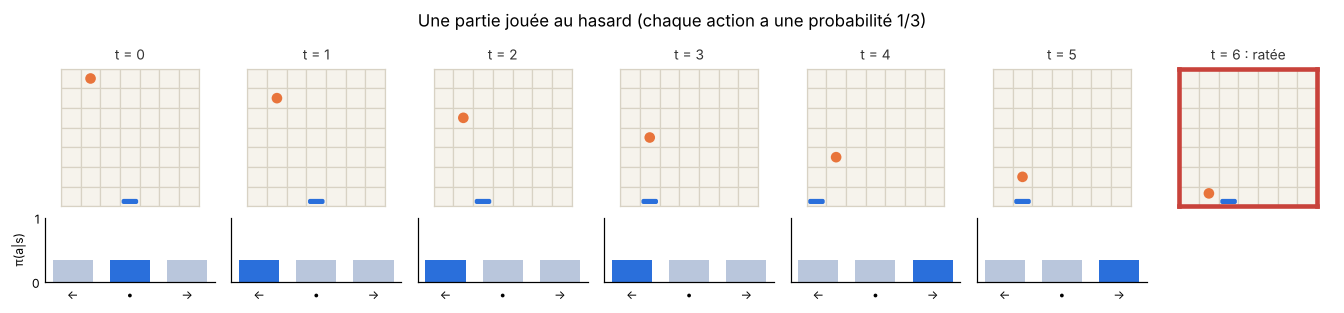

Récompense finale : -1.0


In [4]:
partie_hasard = jouer(Catch(), rng=np.random.default_rng(0), ball_x=1)
film(partie_hasard, "Une partie jouée au hasard (chaque action a une probabilité 1/3)")
print("Récompense finale :", partie_hasard["recompenses"][-1])

Avec ce joueur, la raquette fait une marche aléatoire indépendante de la balle. La probabilité de réussite vaut donc exactement
$$\sum_x P(x_{\text{balle}} = x)\, P(x_{\text{raquette}} = x) = \frac{1}{7}\sum_x P(x_{\text{raquette}} = x) = \frac{1}{7} \approx 14{,}3\,\%.$$
Vérifions par simulation :

In [5]:
rng = np.random.default_rng(0)
env = Catch(rng=rng)
n, reussites = 20_000, 0
for _ in range(n):
    env.reset()
    done = False
    while not done:
        _, _, done = env.step(int(rng.integers(3)))
    reussites += env.caught
print(f"Taux de réussite d'un joueur au hasard : {reussites / n:.1%}  (théorie : {1 / 7:.1%})")

Taux de réussite d'un joueur au hasard : 14.3%  (théorie : 14.3%)


## 2. La politique softmax et son gradient

On cherche une politique **stochastique** paramétrée $\pi_\theta(a \mid s)$. Le choix le plus simple est une table de préférences $\theta \in \mathbb{R}^{343 \times 3}$, transformée en probabilités par une softmax sur chaque ligne :
$$\pi_\theta(a \mid s) = \frac{e^{\theta_{s,a}}}{\sum_{b} e^{\theta_{s,b}}}.$$
Avec $\theta = 0$, la politique est uniforme : c'est le joueur au hasard de la section 1.

REINFORCE a besoin du gradient de $\log \pi_\theta(a \mid s)$. Comme $\log \pi_\theta(a \mid s) = \theta_{s,a} - \log \sum_b e^{\theta_{s,b}}$, on obtient
$$\frac{\partial \log \pi_\theta(a \mid s)}{\partial \theta_{s',b}} = \mathbf{1}\{s' = s\}\,\big(\mathbf{1}\{b = a\} - \pi_\theta(b \mid s)\big).$$
Seule la ligne $s$ de la table est concernée. Le gradient augmente la préférence de l'action jouée et diminue celle des autres en proportion de leur probabilité ; ses composantes somment à zéro.

In [6]:
def softmax(z):
    z = z - z.max()          # stabilité numérique, ne change pas le résultat
    e = np.exp(z)
    return e / e.sum()


class PolitiqueSoftmax:
    def __init__(self, n_states, n_actions):
        self.theta = np.zeros((n_states, n_actions))   # θ = 0 : politique uniforme
        self.visites = np.zeros(n_states, dtype=int)   # utilisé à la section 6

    def probs(self, s):
        return softmax(self.theta[s])

    def sample(self, s, rng):
        # tirage par inversion de la fonction de répartition (plus rapide que rng.choice)
        u = rng.random()
        a = int(np.searchsorted(np.cumsum(self.probs(s)), u, side="right"))
        return min(a, self.theta.shape[1] - 1)

    def greedy(self, s):
        return int(np.argmax(self.theta[s]))

    def grad_log(self, s, a):
        """∇_θ[s] log π(a|s) = onehot(a) − π(·|s)  (seule la ligne s est non nulle)."""
        g = -self.probs(s)
        g[a] += 1.0
        return g

On vérifie la formule par différences finies, sur une ligne de préférences tirée au hasard :

In [7]:
rng = np.random.default_rng(0)
pol_test = PolitiqueSoftmax(n_states=1, n_actions=3)
pol_test.theta[0] = rng.normal(size=3)
s, a, eps = 0, 2, 1e-6

analytique = pol_test.grad_log(s, a)
numerique = np.zeros(3)
for b in range(3):
    plus, moins = pol_test.theta[0].copy(), pol_test.theta[0].copy()
    plus[b] += eps
    moins[b] -= eps
    numerique[b] = (np.log(softmax(plus)[a]) - np.log(softmax(moins)[a])) / (2 * eps)

print("θ[s]                  :", np.round(pol_test.theta[0], 4))
print("π(·|s)                :", np.round(pol_test.probs(s), 4))
print("gradient exact        :", np.round(analytique, 6))
print("différences finies    :", np.round(numerique, 6))
print(f"écart maximal         : {np.abs(analytique - numerique).max():.1e}")
print(f"somme des composantes : {analytique.sum():.1e}")

θ[s]                  : [ 0.1257 -0.1321  0.6404]
π(·|s)                : [0.2902 0.2242 0.4855]
gradient exact        : [-0.290204 -0.224248  0.514452]
différences finies    : [-0.290204 -0.224248  0.514452]
écart maximal         : 1.1e-10
somme des composantes : -1.1e-16


## 3. L'algorithme REINFORCE

**Objectif.** On veut maximiser le retour moyen $J(\theta) = \mathbb{E}_{\tau \sim \pi_\theta}[G_0]$, où $\tau = (s_0, a_0, r_1, \dots, s_{T-1}, a_{T-1}, r_T)$ est une partie et $G_t = \sum_{k=t+1}^{T} \gamma^{k-t-1} r_k$ le retour à partir du pas $t$.

**Astuce de la log-dérivée.** On a $\nabla_\theta \mathbb{E}_{\tau}[G_0] = \mathbb{E}_{\tau}\big[G_0\, \nabla_\theta \log P_\theta(\tau)\big]$. Or
$$\log P_\theta(\tau) = \log p(s_0) + \sum_{t} \log \pi_\theta(a_t \mid s_t) + \sum_t \log p(s_{t+1} \mid s_t, a_t),$$
et seule la somme du milieu dépend de $\theta$ : **on n'a pas besoin de connaître la dynamique du jeu**. Enfin, une action ne peut pas influencer les récompenses déjà reçues, ce qui permet de remplacer $G_0$ par $G_t$ :
$$\nabla_\theta J(\theta) = \mathbb{E}_{\tau \sim \pi_\theta}\Big[\sum_{t=0}^{T-1} G_t \, \nabla_\theta \log \pi_\theta(a_t \mid s_t)\Big].$$

**Estimation Monte-Carlo.** On joue une partie avec la politique courante : la somme entre crochets, calculée sur cette partie, est un estimateur sans biais du gradient. On fait un pas de montée de gradient et on recommence.

**Baseline.** Pour toute fonction $b(s)$ qui ne dépend pas de l'action,
$$\mathbb{E}_{a \sim \pi(\cdot \mid s)}\big[b(s)\,\nabla \log \pi(a \mid s)\big] = b(s) \sum_a \nabla \pi(a \mid s) = b(s)\,\nabla \sum_a \pi(a \mid s) = b(s)\,\nabla 1 = 0.$$
Remplacer $G_t$ par $G_t - b(s_t)$ ne change donc pas l'espérance, mais peut réduire fortement la variance (section 7). Le choix naturel est $b(s) \approx V^\pi(s)$, que l'on apprend lui aussi par Monte-Carlo.

**Algorithme**, avec la politique tabulaire :

```
répéter :
    jouer une partie avec π_θ :  s_0, a_0, r_1, …, s_{T-1}, a_{T-1}, r_T
    pour t = 0, …, T-1 :
        G_t    ← r_{t+1} + γ r_{t+2} + … + γ^{T-t-1} r_T
        δ      ← G_t − b(s_t)                     (δ = G_t sans baseline)
        b(s_t) ← b(s_t) + α_v · δ
        θ[s_t] ← θ[s_t] + α · δ · (onehot(a_t) − π_θ(·|s_t))
```

*Remarque.* La version de Sutton & Barto (§13.3) multiplie aussi la mise à jour par $\gamma^t$. La plupart des implémentations l'omettent et on fait de même ; avec $\gamma = 0{,}99$ et des parties de 6 pas, cela ne change presque rien.

Calculons les retours de la partie au hasard de la section 1 :

In [8]:
def retours(recompenses, gamma):
    """G_t = r_{t+1} + γ G_{t+1}, calculé à rebours."""
    G, sortie = 0.0, []
    for r in reversed(recompenses):
        G = r + gamma * G
        sortie.append(G)
    return sortie[::-1]


G = retours(partie_hasard["recompenses"], gamma=0.99)
print(" t | action  | r_{t+1} |    G_t")
for t, (a, r, g) in enumerate(zip(partie_hasard["actions"], partie_hasard["recompenses"], G)):
    print(f"{t:>2} | {Catch.ACTIONS[a]:<7} | {r:>+7.0f} | {g:+.4f}")

 t | action  | r_{t+1} |    G_t
 0 | rester  |      +0 | -0.9510
 1 | gauche  |      +0 | -0.9606
 2 | gauche  |      +0 | -0.9703
 3 | gauche  |      +0 | -0.9801
 4 | droite  |      +0 | -0.9900
 5 | droite  |      -1 | -1.0000


Seule la dernière récompense est non nulle, donc $G_t = \gamma^{T-1-t}\, r_T$ : toutes les actions d'une partie reçoivent presque le même signal, positif si la balle est attrapée et négatif sinon. Une partie seule ne dit pas quelle action était bonne. C'est en accumulant beaucoup de parties que l'algorithme démêle quelles actions, dans quels états, mènent au succès.

Voici l'entraînement proprement dit, plus quelques utilitaires.

In [9]:
def entrainer(env, pol, n_parties, rng, alpha=0.5, gamma=0.99, V=None, alpha_v=0.2):
    """REINFORCE : une mise à jour après chaque partie.
    Si V est un tableau, il sert de baseline b(s) ≈ V(s) et est appris en même temps.
    Renvoie un tableau de 0/1 (balle attrapée ou non) pour chaque partie."""
    reussites = np.zeros(n_parties)
    for k in range(n_parties):
        # (a) jouer une partie avec la politique courante
        etats, actions, recompenses = [], [], []
        s, done = env.reset(), False
        while not done:
            a = pol.sample(s, rng)
            s_suivant, r, done = env.step(a)
            etats.append(s)
            actions.append(a)
            recompenses.append(r)
            s = s_suivant
        # (b) retours G_t
        G = retours(recompenses, gamma)
        # (c) montée de gradient, pas par pas. Un état n'apparaît qu'une fois par
        #     partie (la balle descend toujours) : mettre à jour au fil de la boucle
        #     revient à utiliser la politique qui a joué la partie.
        for s, a, G_t in zip(etats, actions, G):
            delta = G_t - (V[s] if V is not None else 0.0)
            if V is not None:
                V[s] += alpha_v * delta
            pol.theta[s] += alpha * delta * pol.grad_log(s, a)
            pol.visites[s] += 1
        reussites[k] = env.caught
    return reussites


def evaluer(env, pol, rng, n=2000, glouton=False):
    """Taux de balles attrapées sur n parties, sans apprentissage."""
    total = 0
    for _ in range(n):
        s, done = env.reset(), False
        while not done:
            a = pol.greedy(s) if glouton else pol.sample(s, rng)
            s, _, done = env.step(a)
        total += env.caught
    return total / n


def nouvel_agent(graine, width=7, height=7, reward_offset=0.0, baseline=True):
    rng = np.random.default_rng(graine)
    env = Catch(width, height, rng, reward_offset)
    pol = PolitiqueSoftmax(env.n_states, env.n_actions)
    V = np.zeros(env.n_states) if baseline else None
    return env, pol, V, rng


def moyenne_glissante(x, k=100):
    return np.convolve(x, np.ones(k) / k, mode="valid")

## 4. Entraînement

On entraîne un agent pendant 3000 parties avec $\alpha = 0{,}5$, $\gamma = 0{,}99$ et une baseline $V(s)$ apprise avec $\alpha_v = 0{,}2$. On garde une copie de la table $\theta$ après 0, 100, 400 et 3000 parties, pour rejouer des parties à ces différents stades dans la section 5 (traits pointillés orange sur la courbe).

3000 parties jouées en 0.8 s
Réussite pendant les 100 dernières parties d'entraînement : 100%
Politique finale, stochastique : 99.2%
Politique finale, gloutonne    : 100.0%


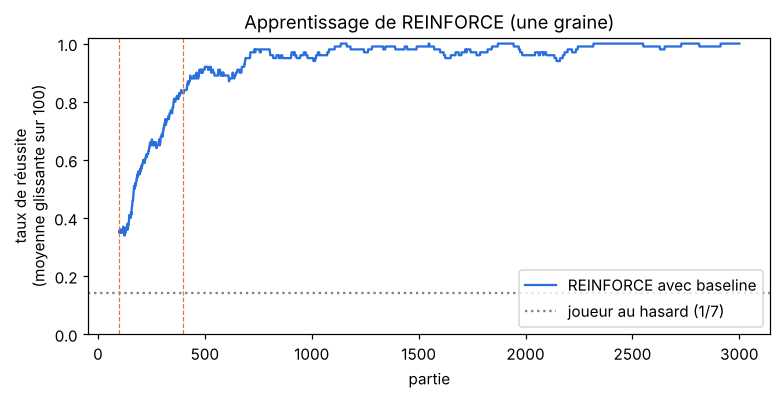

In [10]:
env_a, pol_a, V_a, rng_a = nouvel_agent(graine=0)
instantanes = {0: pol_a.theta.copy()}          # copies de θ pour la section 5
reussites = np.zeros(0)
t0 = time.time()
for jalon in (100, 400, 3000):
    r = entrainer(env_a, pol_a, jalon - len(reussites), rng_a, V=V_a)
    reussites = np.concatenate([reussites, r])
    instantanes[jalon] = pol_a.theta.copy()
print(f"3000 parties jouées en {time.time() - t0:.1f} s")
print(f"Réussite pendant les 100 dernières parties d'entraînement : {reussites[-100:].mean():.0%}")
print(f"Politique finale, stochastique : {evaluer(env_a, pol_a, rng_a):.1%}")
print(f"Politique finale, gloutonne    : {evaluer(env_a, pol_a, rng_a, glouton=True):.1%}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(np.arange(100, len(reussites) + 1), moyenne_glissante(reussites), color=COUL["raquette"],
        label="REINFORCE avec baseline")
ax.axhline(1 / 7, ls=":", color="grey", label="joueur au hasard (1/7)")
for jalon in (100, 400):
    ax.axvline(jalon, ls="--", lw=0.8, color=COUL["balle"])
ax.set_xlabel("partie")
ax.set_ylabel("taux de réussite\n(moyenne glissante sur 100)")
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right")
ax.set_title("Apprentissage de REINFORCE (une graine)")
plt.show()

En quelques centaines de parties, le taux de réussite passe de 1/7 à plus de 90 %, puis s'approche de 100 %. La politique gloutonne (toujours l'action la plus probable) est parfaite ; la politique stochastique rate encore de temps en temps, parce qu'elle garde un peu de probabilité sur les mauvaises actions.

## 5. Regarder l'agent jouer

On rejoue la **même** partie, avec la balle partant de la colonne 0 (tout à gauche) et le même tirage aléatoire, en figeant la politique à différents moments de l'entraînement. Sous chaque image, on voit les probabilités se concentrer peu à peu sur la bonne action.

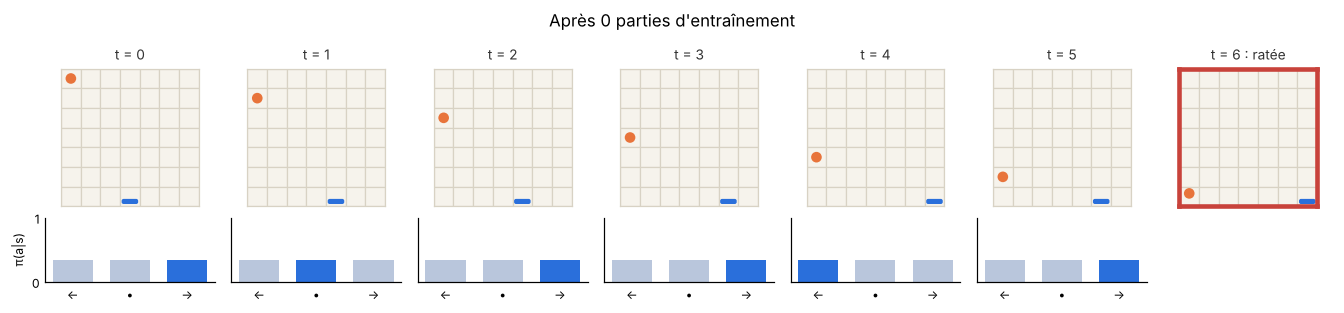

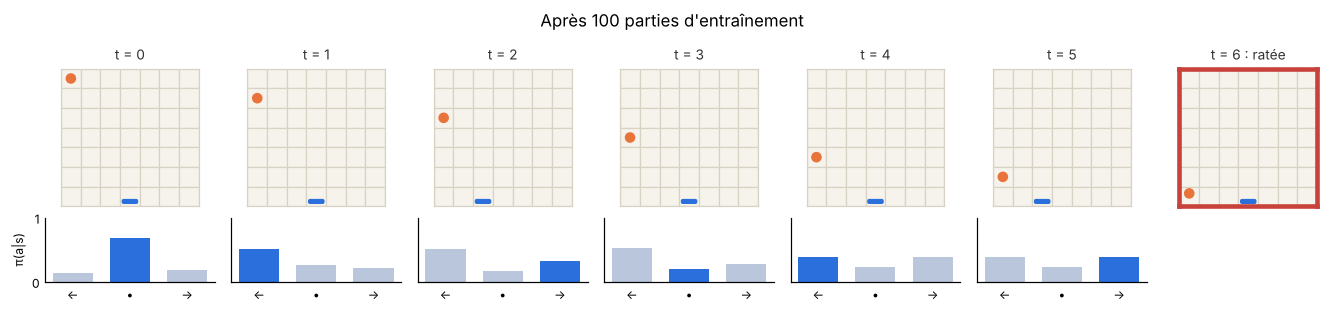

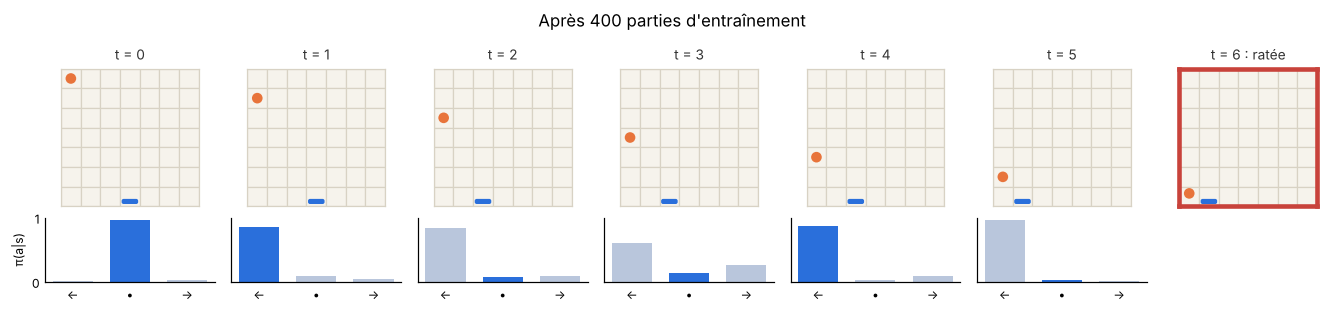

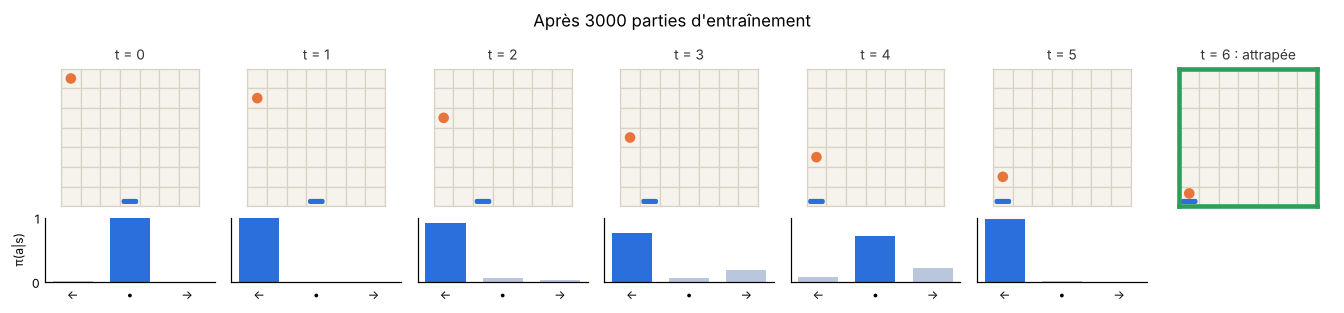

In [11]:
def politique_depuis(theta):
    pol = PolitiqueSoftmax(*theta.shape)
    pol.theta = theta.copy()
    return pol


for jalon, theta in instantanes.items():
    partie = jouer(env_a, politique_depuis(theta), rng=np.random.default_rng(42), ball_x=0)
    film(partie, f"Après {jalon} parties d'entraînement")

Il arrive que l'agent entraîné « perde » un pas, par exemple en restant immobile au début alors que la balle est loin. Ce n'est pas une erreur : avec 6 pas pour parcourir au plus 3 colonnes, il a de la marge, et rien ne pénalise l'attente (voir la section 6 et l'exercice 1).

Une vue d'ensemble : pour chaque colonne de départ, la dernière image d'une partie jouée au hasard (en haut) et d'une partie jouée par l'agent entraîné (en bas).

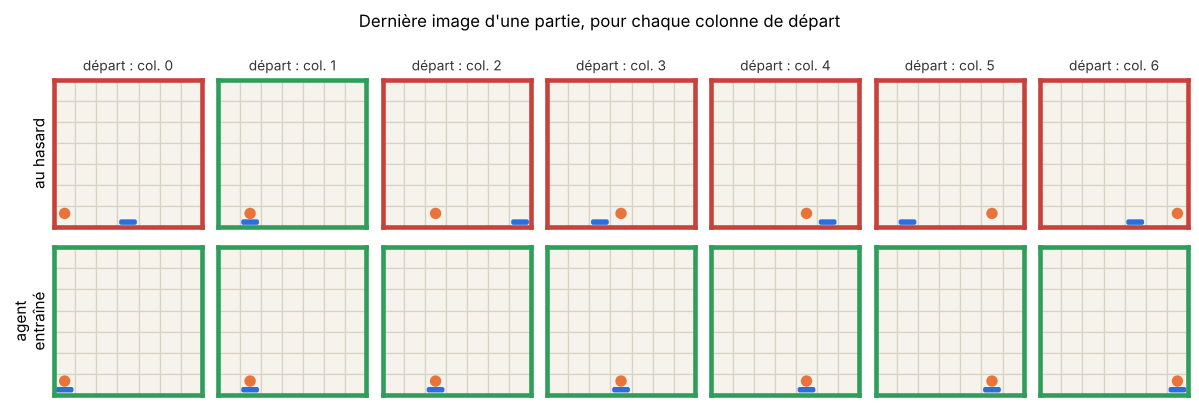

In [12]:
fig, axes = plt.subplots(2, 7, figsize=(11, 3.9))
rng_m = np.random.default_rng(5)
for ligne, (politique, nom) in enumerate([(None, "au hasard"), (pol_a, "agent\nentraîné")]):
    for x in range(7):
        p = jouer(env_a, politique, rng=rng_m, ball_x=x)
        dessiner(axes[ligne, x], p["frames"][-1], env_a.W, env_a.H,
                 titre=f"départ : col. {x}" if ligne == 0 else None, issue=p["attrapee"])
    axes[ligne, 0].set_ylabel(nom, fontsize=10)
fig.suptitle("Dernière image d'une partie, pour chaque colonne de départ", fontsize=11)
fig.tight_layout()
plt.show()

## 6. Ce que l'agent a appris

Comme les déplacements ne coûtent rien, beaucoup d'états laissent de la marge. On classe donc chaque état selon la distance $d = |x_{\text{balle}} - x_{\text{raquette}}|$ et le nombre $k$ de pas restants :

- **libre** ($d \le k - 2$) : les trois actions laissent la balle rattrapable ;
- **serré** ($d = k - 1$) : s'éloigner de la balle la fait perdre ;
- **critique** ($d = k$) : une seule action convient, aller vers la balle ;
- **perdu** ($d > k$) : plus rien ne permet de l'attraper.

Les cartes ci-dessous montrent trois hauteurs de la balle. En abscisse, la colonne de la balle ; en ordonnée, celle de la raquette. Au-dessus de la diagonale, la balle est à droite de la raquette, en dessous elle est à gauche.

- Dans les états serrés et critiques, la couleur donne la probabilité que l'agent choisisse une action qui sauve encore la balle : vert, il ne se trompe pas ; rouge, il se trompe.
- Les états critiques sont encadrés en noir.
- Le symbole est l'action la plus probable et le petit nombre le nombre de visites pendant l'entraînement.
- Aux bords, le mur peut neutraliser un mouvement ; le calcul en tient compte.

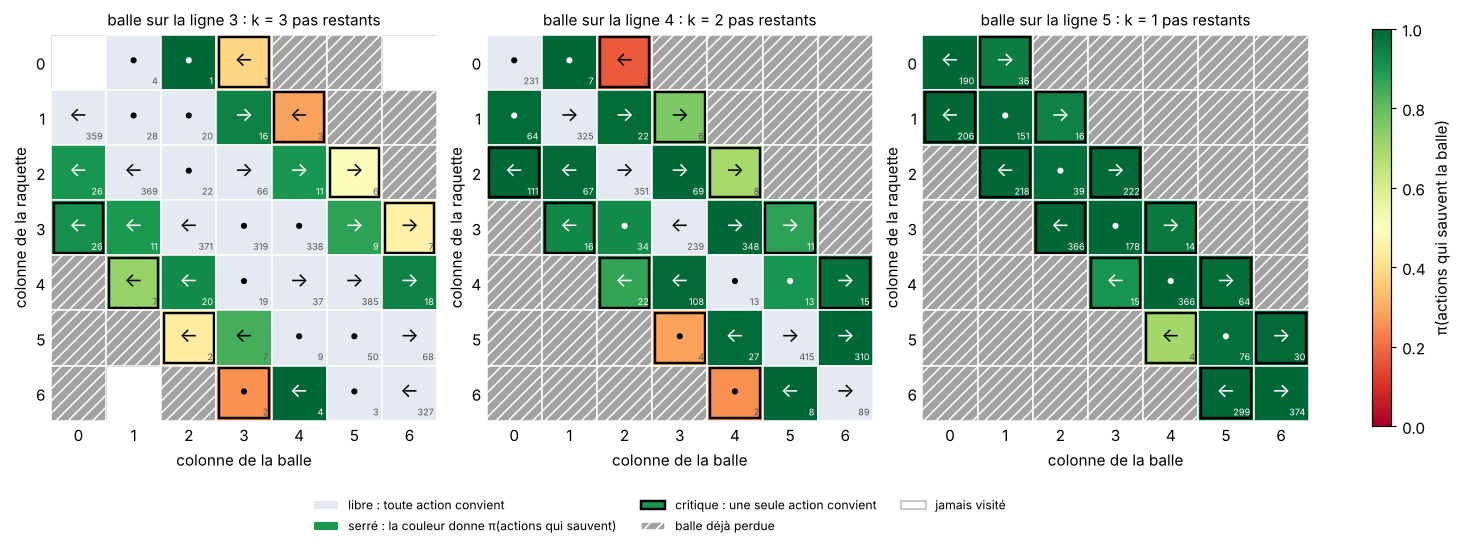

In [13]:
import matplotlib
from matplotlib.patches import Patch


def statut(env, s):
    """Classe un état selon la distance d balle-raquette et le nombre k de pas restants."""
    y, bx, px = env.decode(s)
    k, d = env.H - 1 - y, abs(bx - px)
    if d > k:
        return "perdu"
    if d == k:
        return "critique"
    return "serré" if d == k - 1 else "libre"


def actions_qui_sauvent(env, s):
    """Actions après lesquelles la balle reste rattrapable (calcul exact, murs compris)."""
    y, bx, px = env.decode(s)
    k = env.H - 1 - y
    return [a for a in range(3)
            if abs(bx - int(np.clip(px + a - 1, 0, env.W - 1))) <= k - 1]


def carte_politique(env, pol, lignes=(3, 4, 5)):
    cmap = plt.get_cmap("RdYlGn")
    libre, perdu = "#e4e9f2", "#a3a3a3"
    fig, axes = plt.subplots(1, len(lignes), figsize=(4.4 * len(lignes), 4.9),
                             constrained_layout=True)
    for ax, y in zip(axes, lignes):
        for bx in range(env.W):
            for px in range(env.W):
                s = env.encode(y, bx, px)
                st, n = statut(env, s), pol.visites[s]
                coin = (bx - 0.5, px - 0.5)
                if n == 0:
                    ax.add_patch(Rectangle(coin, 1, 1, facecolor="white",
                                           edgecolor="#dddddd", lw=0.6))
                    continue
                if st == "perdu":
                    ax.add_patch(Rectangle(coin, 1, 1, facecolor=perdu, edgecolor="white",
                                           lw=1, hatch="///"))
                    continue
                p = pol.probs(s)
                fond = libre if st == "libre" else cmap(p[actions_qui_sauvent(env, s)].sum())
                ax.add_patch(Rectangle(coin, 1, 1, facecolor=fond, edgecolor="white", lw=1))
                r, g, b = matplotlib.colors.to_rgb(fond)
                sombre = 0.299 * r + 0.587 * g + 0.114 * b < 0.5
                ax.text(bx, px - 0.06, Catch.FLECHES[int(np.argmax(p))], ha="center",
                        va="center", fontsize=13, color="white" if sombre else "black")
                ax.text(bx + 0.44, px + 0.44, str(n), ha="right", va="bottom", fontsize=6,
                        color="white" if sombre else "#555555")
                if st == "critique":
                    ax.add_patch(Rectangle((bx - 0.45, px - 0.45), 0.9, 0.9, fill=False,
                                           edgecolor="black", lw=1.6))
        ax.set_xlim(-0.5, env.W - 0.5)
        ax.set_ylim(env.W - 0.5, -0.5)
        ax.set_aspect("equal")
        ax.set_xticks(range(env.W))
        ax.set_yticks(range(env.W))
        ax.tick_params(length=0)
        for bord in ax.spines.values():
            bord.set_visible(False)
        ax.set_title(f"balle sur la ligne {y} : k = {env.H - 1 - y} pas restants", fontsize=10)
        ax.set_xlabel("colonne de la balle")
        ax.set_ylabel("colonne de la raquette")
    legende = [Patch(facecolor=libre, label="libre : toute action convient"),
               Patch(facecolor=cmap(0.9), label="serré : la couleur donne π(actions qui sauvent)"),
               Patch(facecolor=cmap(0.9), edgecolor="black", lw=1.6,
                     label="critique : une seule action convient"),
               Patch(facecolor=perdu, edgecolor="white", hatch="///", label="balle déjà perdue"),
               Patch(facecolor="white", edgecolor="#bbbbbb", label="jamais visité")]
    fig.legend(handles=legende, loc="upper center", bbox_to_anchor=(0.45, 0.02), ncol=3,
               fontsize=8, frameon=False)
    fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 1)), ax=list(axes),
                 shrink=0.75, label="π(actions qui sauvent la balle)")
    plt.show()


carte_politique(env_a, pol_a)

Faisons le bilan sur tous les états visités (hors dernière ligne, où la partie est finie) :

In [14]:
bilan = {st: dict(etats=0, visites=0, ok=0, proba=0.0)
         for st in ("libre", "serré", "critique", "perdu")}
erreurs = []
for s in range(env_a.n_states):
    y, bx, px = env_a.decode(s)
    n = pol_a.visites[s]
    if y == env_a.H - 1 or n == 0:
        continue
    st = statut(env_a, s)
    b = bilan[st]
    b["etats"] += 1
    b["visites"] += n
    if st == "perdu":
        continue
    sauvent, p = actions_qui_sauvent(env_a, s), pol_a.probs(s)
    b["ok"] += int(np.argmax(p) in sauvent)
    b["proba"] += n * p[sauvent].sum()
    if np.argmax(p) not in sauvent:
        erreurs.append((st, y, bx, px, n, p))

print(f"{'statut':<9}{'états':>7}{'visites':>9}   {'action la + probable bonne':>27}"
      f"   {'π(actions qui sauvent)*':>24}")
for st, b in bilan.items():
    if st == "perdu":
        print(f"{st:<9}{b['etats']:>7}{b['visites']:>9}   {'—':>27}   {'—':>24}")
    else:
        bonne = f"{b['ok']} / {b['etats']}"
        print(f"{st:<9}{b['etats']:>7}{b['visites']:>9}   {bonne:>27}"
              f"   {b['proba'] / b['visites']:>24.1%}")
print("* moyenne pondérée par le nombre de visites\n")

print("États où l'action la plus probable fait perdre la balle :")
for st, y, bx, px, n, p in erreurs:
    print(f"  {st:<8} ligne {y}, balle {bx}, raquette {px} : {n} visite(s), "
          f"π = [{p[0]:.2f}, {p[1]:.2f}, {p[2]:.2f}]")

statut     états  visites    action la + probable bonne    π(actions qui sauvent)*
libre         74    13378                       74 / 74                     100.0%
serré         37     2632                       37 / 37                      98.9%
critique      34     1760                       26 / 34                      97.0%
perdu         62      230                             —                          —
* moyenne pondérée par le nombre de visites

États où l'action la plus probable fait perdre la balle :
  critique ligne 2, balle 5, raquette 1 : 3 visite(s), π = [0.27, 0.49, 0.23]
  critique ligne 2, balle 6, raquette 2 : 5 visite(s), π = [0.33, 0.37, 0.30]
  critique ligne 3, balle 3, raquette 0 : 1 visite(s), π = [0.38, 0.23, 0.38]
  critique ligne 3, balle 3, raquette 6 : 2 visite(s), π = [0.26, 0.44, 0.30]
  critique ligne 3, balle 4, raquette 1 : 3 visite(s), π = [0.38, 0.34, 0.28]
  critique ligne 4, balle 2, raquette 0 : 3 visite(s), π = [0.48, 0.35, 0.17]
  critique lig

**Lecture.**

- **États libres.** Toute action convient, et l'agent n'a rien eu à apprendre.
- **États serrés et critiques.** C'est là que se joue la partie. Dans ceux que l'agent rencontre souvent, il a appris la règle « aller vers la balle » sans qu'on la lui donne : il n'a reçu que des +1 et des −1 en fin de partie.
- **Les erreurs restantes.** Elles se trouvent dans des états très rarement visités (quelques visites seulement), où la politique est restée presque uniforme. C'est une limite des politiques tabulaires : rien n'est appris dans un état que l'on ne visite pas, alors qu'une politique qui généralise appliquerait la même règle partout (exercice 5).
- **États perdus.** Ils ne reçoivent aucun signal utile : toutes les actions y mènent à −1, donc avec la baseline $\delta = G_t - V(s)$ tend vers 0.
- **Zones vides.** Ce sont des états jamais rencontrés, par exemple la raquette tout au bord alors que la balle est de l'autre côté. Une politique qui suit la balle ne s'en éloigne jamais beaucoup.

## 7. Pourquoi une baseline ?

Ajouter une constante $c$ à la récompense finale ne change ni le jeu, ni la politique optimale, ni le gradient $\nabla J$, puisque $\mathbb{E}[\nabla \log \pi] = 0$. Mais cela change énormément la **variance** de l'estimateur sans baseline. Avec des récompenses $+11/+9$ au lieu de $+1/-1$, chaque partie, gagnée ou perdue, pousse à rejouer *toutes* les actions qu'on vient de jouer ; seule la petite différence entre 11 et 9 porte l'information utile.

### 7.1 Mesure directe de la variance

On fixe la politique uniforme et on estime la dérivée de $J$ dans la direction $d$ « aller vers la balle » : dans chaque état, $d$ augmente la préférence de l'action qui rapproche la raquette de la balle. Chaque partie fournit une estimation $\hat g \cdot d$. Pour la politique uniforme, elle vaut $\sum_t (G_t - b_t)\,\big(\mathbf{1}\{a_t \text{ rapproche}\} - \tfrac13\big)$ : c'est une corrélation entre le retour et le nombre de « bons » mouvements.

On compare quatre estimateurs : récompenses $\pm 1$ ou $+11/+9$, sans baseline ou avec une baseline $b_t$ égale au retour moyen au pas $t$. Cette baseline est estimée sur un lot de parties indépendant, pour ne pas introduire de biais.

In [15]:
def direction_vers_balle(env):
    """Direction d : dans chaque état, +2/3 sur l'action qui rapproche la raquette
    de la balle et −1/3 sur les deux autres."""
    d = np.zeros((env.n_states, 3))
    for s in range(env.n_states):
        _, bx, px = env.decode(s)
        bonne = 2 if bx > px else 0 if bx < px else 1
        d[s] = -1 / 3
        d[s, bonne] += 1
    return d


def derivees_directionnelles(env, pol, d, n, rng, gamma=0.99, b_t=None):
    """n estimations indépendantes (une par partie) de ∇J · d.
    Renvoie aussi les retours G_t de chaque partie."""
    z, tous_G = np.zeros(n), []
    for i in range(n):
        etats, actions, recompenses = [], [], []
        s, done = env.reset(), False
        while not done:
            a = pol.sample(s, rng)
            s_suivant, r, done = env.step(a)
            etats.append(s)
            actions.append(a)
            recompenses.append(r)
            s = s_suivant
        G = retours(recompenses, gamma)
        for t, (s, a, G_t) in enumerate(zip(etats, actions, G)):
            b = b_t[t] if b_t is not None else 0.0
            z[i] += (G_t - b) * (pol.grad_log(s, a) @ d[s])
        tous_G.append(G)
    return z, np.array(tous_G)


n = 4000
print(f"{'récompenses':<12} {'baseline':<9} {'moyenne':>8} {'écart-type':>11} "
      f"{'parties pour ±10 %':>19}")
for offset in (0.0, 10.0):
    rng = np.random.default_rng(1)
    env_v = Catch(rng=rng, reward_offset=offset)
    pol_u = PolitiqueSoftmax(env_v.n_states, 3)               # politique uniforme
    d = direction_vers_balle(env_v)
    z_sans, G = derivees_directionnelles(env_v, pol_u, d, n, rng)
    b_t = G.mean(axis=0)                  # baseline estimée sur ce premier lot...
    z_avec, _ = derivees_directionnelles(env_v, pol_u, d, n, rng, b_t=b_t)  # ...utilisée sur un autre
    nom = "+1 / −1" if offset == 0 else "+11 / +9"
    for z, avec in ((z_sans, "non"), (z_avec, "oui")):
        m, e = z.mean(), z.std()
        besoin = f"{int((e / (0.1 * m)) ** 2):,}".replace(",", " ")
        print(f"{nom:<12} {avec:<9} {m:>8.3f} {e:>11.3f} {besoin:>19}")

récompenses  baseline   moyenne  écart-type  parties pour ±10 %
+1 / −1      non          0.417       1.044                 627
+1 / −1      oui          0.418       1.059                 642
+11 / +9     non          0.314      10.859             119 950
+11 / +9     oui          0.418       1.059                 642


- **Pas de biais.** Les quatre estimateurs ont la même moyenne, aux fluctuations statistiques près : la baseline ne change pas ce que l'on estime.
- **Variance.** Sans baseline et avec des récompenses décalées, l'écart-type est environ dix fois plus grand. Comme le nombre de parties nécessaires croît comme le carré de l'écart-type, il en faut environ deux ordres de grandeur de plus pour la même précision.
- **Le décalage disparaît avec la baseline.** Les deux lignes « oui » sont identiques : $G_t$ et $b_t$ sont décalés de la même quantité, donc $G_t - b_t$ ne dépend plus du décalage.
- **Avec des récompenses $\pm 1$,** la baseline n'apporte presque rien ici : le signe du retour dit déjà si la partie est gagnée ou perdue.

### 7.2 Effet sur l'apprentissage

On entraîne maintenant 5 agents (5 graines) pour chacune des quatre configurations et on moyenne les courbes.

20 entraînements en 20 s

sans baseline, récompenses +1/−1         réussite finale : 99.1%   (par graine : 99%, 99%, 99%, 99%, 99%)
avec baseline, récompenses +1/−1         réussite finale : 99.0%   (par graine : 99%, 99%, 99%, 99%, 99%)
sans baseline, récompenses +11/+9        réussite finale : 19.2%   (par graine : 27%, 0%, 43%, 14%, 12%)
avec baseline, récompenses +11/+9        réussite finale : 67.4%   (par graine : 55%, 70%, 58%, 86%, 69%)


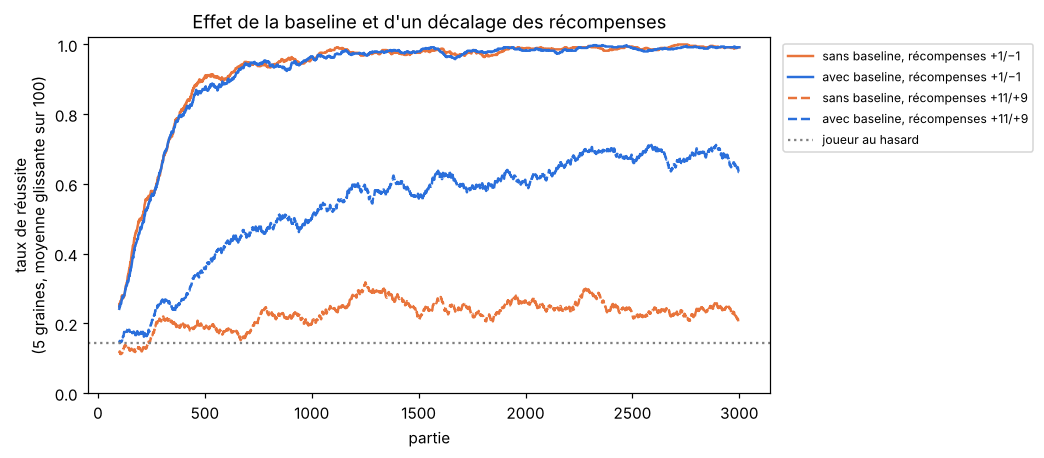

In [16]:
def experience(n_parties=3000, graines=range(5), baseline=True, reward_offset=0.0):
    courbes, finales = [], []
    for g in graines:
        env, pol, V, rng = nouvel_agent(g, reward_offset=reward_offset, baseline=baseline)
        courbes.append(entrainer(env, pol, n_parties, rng, V=V))
        finales.append(evaluer(env, pol, rng))
    return np.mean(courbes, axis=0), np.array(finales)


t0 = time.time()
resultats = {}
for offset in (0.0, 10.0):
    for baseline in (False, True):
        resultats[(offset, baseline)] = experience(baseline=baseline, reward_offset=offset)
print(f"20 entraînements en {time.time() - t0:.0f} s\n")

fig, ax = plt.subplots(figsize=(8, 4.2))
for (offset, baseline), (courbe, finales) in resultats.items():
    nom = (f"{'avec' if baseline else 'sans'} baseline, "
           f"récompenses {'+1/−1' if offset == 0 else '+11/+9'}")
    print(f"{nom:<40} réussite finale : {finales.mean():5.1%}   "
          f"(par graine : {', '.join(f'{f:.0%}' for f in finales)})")
    ax.plot(np.arange(100, len(courbe) + 1), moyenne_glissante(courbe), label=nom,
            color=COUL["raquette"] if baseline else COUL["balle"],
            ls="-" if offset == 0 else "--", lw=1.6)
ax.axhline(1 / 7, ls=":", color="grey", label="joueur au hasard")
ax.set_xlabel("partie")
ax.set_ylabel("taux de réussite\n(5 graines, moyenne glissante sur 100)")
ax.set_ylim(0, 1.02)
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("Effet de la baseline et d'un décalage des récompenses")
plt.show()

- **Récompenses $\pm 1$.** La baseline ne change presque rien : les retours sont déjà de signe informatif et les parties sont courtes, donc la variance est faible.
- **Récompenses $+11/+9$ sans baseline.** Les premières parties renforcent massivement les actions jouées, quelles qu'elles soient. La softmax sature sur ces premiers choix, l'exploration disparaît et la politique se fige loin de l'optimum. Selon la graine, elle finit plus ou moins loin, parfois même sous le niveau du joueur au hasard.
- **Récompenses $+11/+9$ avec baseline.** La baseline rétablit le bon signal (« mieux » ou « moins bien » que d'habitude), et l'apprentissage repart. Il reste plus lent que dans le cas $\pm 1$, parce que $V$ part de 0 : les toutes premières mises à jour, avec $\delta \approx 10$, ont déjà fortement déformé la politique avant que la baseline ait appris. L'exercice 4 de la section 9 propose d'y remédier.

## 8. Le lien avec le bandit

Avec $H = 2$, la balle n'a qu'une ligne à descendre : il n'y a **qu'une seule décision** par partie. Le jeu devient un **bandit contextuel** : le contexte est la colonne de la balle, les bras sont les trois actions, et la récompense arrive immédiatement. Si l'on fixe en plus la colonne de départ, c'est un bandit à 3 bras ordinaire.

Dans ce cas $T = 1$ et $G_0 = r$. La mise à jour de REINFORCE avec baseline s'écrit, dans chaque contexte $s$ :
$$\theta_{s,b} \leftarrow \theta_{s,b} + \alpha\,(r - \bar r_s)\,\big(\mathbf{1}\{b = a\} - \pi(b \mid s)\big),$$
où $\bar r_s$ est une moyenne mobile des récompenses. C'est exactement l'algorithme *gradient bandit* de Sutton & Barto (§2.8).

La raquette part du centre (colonne 3) et ne peut bouger que d'une case : seules les balles des colonnes 2, 3 et 4 sont rattrapables, d'où un taux de réussite maximal de $3/7 \approx 42{,}9\,\%$.

Politique apprise, contexte par contexte  [π(gauche), π(rester), π(droite)] :
  balle en colonne 0 : [0.66, 0.21, 0.13]  -> gauche 
  balle en colonne 1 : [0.38, 0.16, 0.46]  -> droite 
  balle en colonne 2 : [1.00, 0.00, 0.00]  -> gauche (attrapée)
  balle en colonne 3 : [0.00, 1.00, 0.00]  -> rester (attrapée)
  balle en colonne 4 : [0.00, 0.00, 0.99]  -> droite (attrapée)
  balle en colonne 5 : [0.29, 0.28, 0.43]  -> droite 
  balle en colonne 6 : [0.26, 0.45, 0.29]  -> rester 

La politique gloutonne attrape la balle dans 3 contextes sur 7, soit 42.9% des parties (maximum possible : 3/7 = 42.9%).


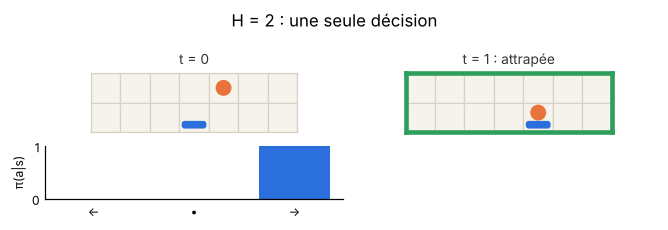

In [17]:
env_b, pol_b, V_b, rng_b = nouvel_agent(graine=0, height=2)
reussites_b = entrainer(env_b, pol_b, 2000, rng_b, V=V_b)

centre = env_b.W // 2
print("Politique apprise, contexte par contexte  [π(gauche), π(rester), π(droite)] :")
gagnes = 0
for bx in range(env_b.W):
    p = pol_b.probs(env_b.encode(0, bx, centre))
    a = int(np.argmax(p))
    attrape = int(np.clip(centre + a - 1, 0, env_b.W - 1)) == bx
    gagnes += attrape
    print(f"  balle en colonne {bx} : [{p[0]:.2f}, {p[1]:.2f}, {p[2]:.2f}]"
          f"  -> {Catch.ACTIONS[a]:<6} {'(attrapée)' if attrape else ''}")

# La politique gloutonne est déterministe : son taux de réussite se calcule exactement
print(f"\nLa politique gloutonne attrape la balle dans {gagnes} contextes sur 7, "
      f"soit {gagnes / 7:.1%} des parties (maximum possible : 3/7 = {3 / 7:.1%}).")

film(jouer(env_b, pol_b, rng=np.random.default_rng(0), ball_x=4), "H = 2 : une seule décision")

Pour les colonnes 2, 3 et 4, l'agent a trouvé le bon bras. Pour les colonnes 0, 1, 5 et 6, toutes les actions perdent : avec la baseline, $r - \bar r_s$ tend vers 0, la politique n'a plus rien à apprendre et reste à peu près où les premières parties l'ont laissée.

**REINFORCE est-il un bon algorithme de bandit ?** Pas vraiment. Sur un bandit, les algorithmes de référence (UCB et Thompson sampling dans le cadre stochastique, EXP3 dans le cadre adversarial) ont des garanties de regret : logarithmique en $T$ pour les premiers, en $\sqrt{T K \log K}$ pour EXP3. REINFORCE n'en a pas.

- **Exploration non dirigée.** Elle ne vient que de l'aléa de la politique, qui disparaît quand la softmax se concentre, sans bonus pour les bras mal connus.
- **Sensibilité aux réglages.** Le résultat dépend du pas $\alpha$ et de la baseline, comme on l'a vu à la section 7.
- **Convergence lente.** Même avec le gradient exact, la softmax converge en $O(1/t)$, avec des constantes qui peuvent être très mauvaises (Mei et al., 2020).

Son intérêt est ailleurs : il ne demande qu'une politique différentiable. Il s'applique donc tel quel aux bandits contextuels avec un réseau de neurones, aux espaces d'actions immenses ou continus, et aux problèmes séquentiels comme le jeu complet de ce notebook. Dans ces cas, construire les intervalles de confiance d'UCB ou la loi a posteriori de Thompson devient difficile. Le fine-tuning de modèles de langage par RL en est l'exemple typique : le prompt est le contexte, la réponse entière est l'action et une seule récompense est donnée. On y utilise des variantes de REINFORCE (RLOO) ou des méthodes proches (GRPO).

## 9. Pour aller plus loin

Quelques modifications, de la plus simple à la plus longue :

1. **Pénaliser les déplacements.** Donner −0,05 à chaque pas où la raquette bouge. L'aller-retour inutile que l'on voit parfois disparaît-il ? Les récompenses intermédiaires rendent $G_t$ différent d'un pas à l'autre.
2. **Le facteur $\gamma^t$.** Ajouter le facteur $\gamma^t$ de Sutton & Barto dans la mise à jour et prendre $\gamma = 0{,}9$. Qu'est-ce qui change ?
3. **Réparer le cas $+11/+9$ sans baseline.** Essayer un pas $\alpha$ plus petit, ou un bonus d'entropie $\beta\,\nabla_\theta \mathcal{H}\big(\pi_\theta(\cdot \mid s)\big)$ qui empêche la politique de se figer trop tôt.
4. **Initialiser la baseline.** Dans le cas $+11/+9$ avec baseline, initialiser $V$ à 10 au lieu de 0. L'apprentissage retrouve-t-il la vitesse du cas $\pm 1$ ?
5. **Une politique qui généralise.** Remplacer la table (1029 paramètres) par une politique linéaire sur quelques caractéristiques $\phi(s, a)$, par exemple le signe de $x_{\text{balle}} - x_{\text{raquette}}$ croisé avec l'action. Le gradient devient $\nabla \log \pi(a \mid s) = \phi(s,a) - \sum_b \pi(b \mid s)\,\phi(s,b)$.
6. **Acteur-critique.** Remplacer $G_t$ par $r_{t+1} + \gamma V(s_{t+1})$ et mettre à jour après chaque pas au lieu d'attendre la fin de la partie.
7. **Bandit.** Sur un bandit à 10 bras, comparer le regret de REINFORCE (section 8) à celui d'UCB et de Thompson sampling.
8. **Un jeu plus riche.** Faire tomber la balle en diagonale, avec rebonds sur les bords. L'état doit alors contenir la direction de la balle.

### Une animation de l'agent entraîné

L'agent entraîné à la section 4 joue une balle depuis chaque colonne de départ, avec sa politique gloutonne. L'animation est aussi enregistrée dans le fichier `partie_agent.gif`, à côté du notebook.

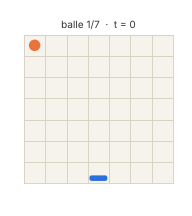

In [18]:
from PIL import Image as PILImage
from IPython.display import Image, display


def image_de(etat, W, H, titre, issue):
    """Rend un état du jeu en image PIL (pour fabriquer le GIF)."""
    fig, ax = plt.subplots(figsize=(2.4, 2.7), dpi=80)
    dessiner(ax, etat, W, H, titre=titre, issue=issue)
    fig.canvas.draw()
    image = PILImage.fromarray(np.asarray(fig.canvas.buffer_rgba())).convert("RGB")
    plt.close(fig)
    return image


images, durees = [], []
for k, x in enumerate([0, 6, 2, 5, 1, 4, 3]):
    p = jouer(env_a, pol_a, glouton=True, ball_x=x)
    for t, etat in enumerate(p["frames"]):
        fin = t == len(p["frames"]) - 1
        images.append(image_de(etat, env_a.W, env_a.H, f"balle {k + 1}/7  ·  t = {t}",
                               p["attrapee"] if fin else None))
        durees.append(900 if fin else 260)

images[0].save("partie_agent.gif", save_all=True, append_images=images[1:],
               duration=durees, loop=0)
display(Image(filename="partie_agent.gif"))

## Références

- R. J. Williams (1992). *Simple statistical gradient-following algorithms for connectionist reinforcement learning*. Machine Learning, 8, 229–256.
- R. S. Sutton et A. G. Barto (2018). *Reinforcement Learning: An Introduction*, 2e édition. §2.8 (gradient bandit), §13.3 (REINFORCE) et §13.4 (REINFORCE avec baseline).
- J. Mei, C. Xiao, Cs. Szepesvári et D. Schuurmans (2020). *On the global convergence rates of softmax policy gradient methods*. ICML.